In [1]:

# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels

# Check library versions
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("YFinance version:", yf.__version__)
print("Statsmodels version:", statsmodels.__version__)

print("\nAll libraries imported successfully!")

Pandas version: 3.0.3
NumPy version: 2.4.6
YFinance version: 1.8.0
Statsmodels version: 0.14.6

All libraries imported successfully!


In [2]:

# Step 2: Download Maybank historical stock data

import os
import pandas as pd
import yfinance as yf

# Define stock ticker and date range
ticker = "1155.KL"
start_date = "2021-01-01"
end_date = "2026-11-22"

# Download daily stock data
maybank = yf.download(
    ticker,
    start=start_date,
    end=end_date,
    interval="1d",
    auto_adjust=False,
    progress=False
)

# Check whether data was downloaded
if maybank.empty:
    raise ValueError("No data downloaded. Please check your internet connection.")

# Handle MultiIndex columns if returned by yfinance
if isinstance(maybank.columns, pd.MultiIndex):
    maybank.columns = maybank.columns.get_level_values(0)

# Convert the Date index into a normal column
maybank = maybank.reset_index()

# Sort data by date
maybank["Date"] = pd.to_datetime(maybank["Date"])
maybank = maybank.sort_values("Date").reset_index(drop=True)

# Remove duplicate dates
maybank = maybank.drop_duplicates(subset="Date")

# Create folder and save the downloaded data
os.makedirs("data/raw", exist_ok=True)

maybank.to_csv(
    "data/raw/maybank_1155_kl.csv",
    index=False
)

# Display download information
print("Download successful!")
print("Total records:", len(maybank))
print("First date:", maybank["Date"].min())
print("Last date:", maybank["Date"].max())

# Display first five records
maybank.head()


Download successful!
Total records: 1440
First date: 2021-01-04 00:00:00
Last date: 2026-11-20 00:00:00


Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2021-01-04,5.632041,8.35,8.48,8.33,8.47,4278900
1,2021-01-05,5.605062,8.31,8.36,8.21,8.34,5386900
2,2021-01-06,5.557846,8.24,8.35,8.20,8.31,4014500
3,2021-01-07,5.584826,8.28,8.28,8.04,8.20,13503300
4,2021-01-08,5.665766,8.40,8.40,8.10,8.24,9074600


In [3]:

# Check the structure and quality of the downloaded data

print("Dataset information:")
maybank.info()

print("\nMissing values:")
print(maybank.isnull().sum())

print("\nStatistical summary:")
maybank.describe()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype        
---  ------     --------------  -----        
 0   Date       1440 non-null   datetime64[s]
 1   Adj Close  1439 non-null   float64      
 2   Close      1439 non-null   float64      
 3   High       1440 non-null   float64      
 4   Low        1440 non-null   float64      
 5   Open       1440 non-null   float64      
 6   Volume     1440 non-null   int64        
dtypes: datetime64[s](1), float64(5), int64(1)
memory usage: 78.9 KB

Missing values:
Price
Date         0
Adj Close    1
Close        1
High         0
Low          0
Open         0
Volume       0
dtype: int64

Statistical summary:


Price,Date,Adj Close,Close,High,Low,Open,Volume
count,1440,1439.000000,1439.000000,1440.000000,1440.000000,1440.000000,1.440000e+03
mean,2023-12-13 14:41:00,7.938798,9.407651,9.458236,9.362174,9.409299,1.038703e+07
min,2021-01-04 00:00:00,5.267813,7.810000,7.940000,7.790000,7.850000,0.000000e+00
25%,2022-06-23 18:00:00,6.692759,8.630000,8.660000,8.590000,8.620000,5.995275e+06
50%,2023-12-12 12:00:00,7.560349,9.090000,9.115000,9.045000,9.090000,8.618450e+06
75%,2025-06-04 06:00:00,9.296490,10.120000,10.180000,10.080000,10.100000,1.264660e+07
max,2026-11-20 00:00:00,11.676455,12.380000,12.420000,12.300000,12.400000,1.078396e+08
std,NaN,1.653454,0.988065,0.998447,0.975749,0.987746,7.469281e+06


In [4]:

# Step 3.1: Load and prepare Maybank data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load historical Maybank data
maybank = pd.read_csv("data/raw/maybank_1155_kl.csv")

# Convert Date column into datetime format
maybank["Date"] = pd.to_datetime(maybank["Date"])

# Sort data from oldest to newest
maybank = maybank.sort_values("Date").reset_index(drop=True)

# Display dataset information
print("Dataset shape:", maybank.shape)

print("\nAvailable columns:")
print(maybank.columns.tolist())

print("\nFirst five records:")
display(maybank.head())


Dataset shape: (1440, 7)

Available columns:
['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']

First five records:


,Date,Adj Close,Close,High,Low,Open,Volume
0,2021-01-04,5.632041,8.35,8.48,8.33,8.47,4278900
1,2021-01-05,5.605062,8.31,8.36,8.21,8.34,5386900
2,2021-01-06,5.557846,8.24,8.35,8.20,8.31,4014500
3,2021-01-07,5.584826,8.28,8.28,8.04,8.20,13503300
4,2021-01-08,5.665766,8.40,8.40,8.10,8.24,9074600


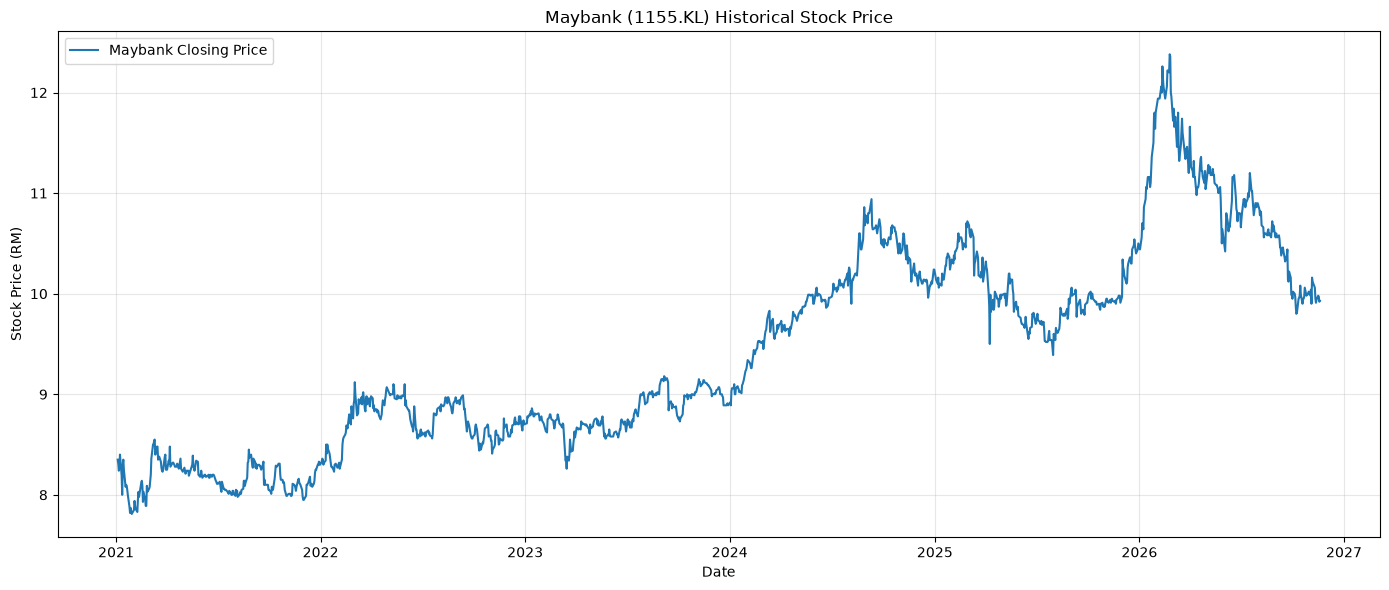

In [5]:

# Step 3.2: Historical Maybank Stock Price

plt.figure(figsize=(14, 6))

plt.plot(
    maybank["Date"],
    maybank["Close"],
    label="Maybank Closing Price"
)

plt.title("Maybank (1155.KL) Historical Stock Price")
plt.xlabel("Date")
plt.ylabel("Stock Price (RM)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart for GitHub
import os
os.makedirs("outputs/figures", exist_ok=True)

plt.savefig(
    "outputs/figures/maybank_historical_price.png",
    dpi=300
)

plt.show()


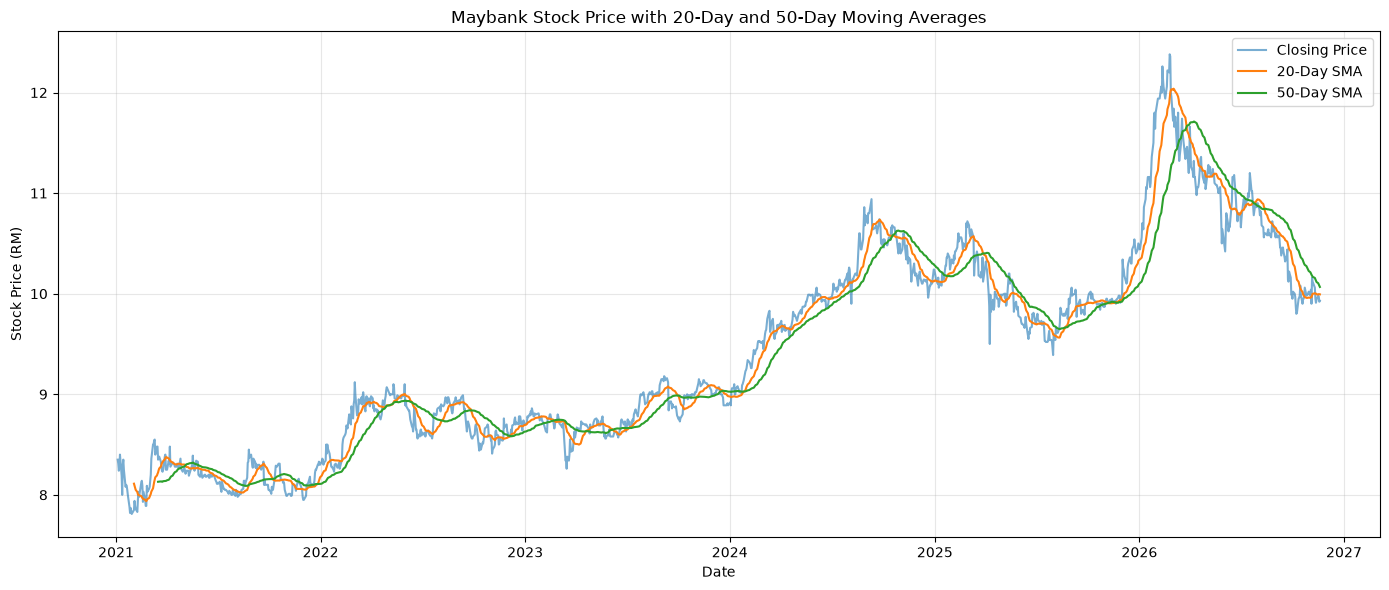

In [6]:

# Step 3.3: Calculate Moving Averages

# Calculate 20-day moving average
maybank["SMA_20"] = maybank["Close"].rolling(window=20).mean()

# Calculate 50-day moving average
maybank["SMA_50"] = maybank["Close"].rolling(window=50).mean()

# Plot stock price and moving averages
plt.figure(figsize=(14, 6))

plt.plot(
    maybank["Date"],
    maybank["Close"],
    label="Closing Price",
    alpha=0.6
)

plt.plot(
    maybank["Date"],
    maybank["SMA_20"],
    label="20-Day SMA"
)

plt.plot(
    maybank["Date"],
    maybank["SMA_50"],
    label="50-Day SMA"
)

plt.title("Maybank Stock Price with 20-Day and 50-Day Moving Averages")
plt.xlabel("Date")
plt.ylabel("Stock Price (RM)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/figures/maybank_moving_averages.png",
    dpi=300
)

plt.show()


In [7]:

# Step 3.4: Descriptive Statistics

print("Descriptive Statistics of Maybank Stock Data")

maybank[["Close", "Volume"]].describe()


Descriptive Statistics of Maybank Stock Data


,Close,Volume
count,1439.000000,1.440000e+03
mean,9.407651,1.038703e+07
std,0.988065,7.469281e+06
min,7.810000,0.000000e+00
25%,8.630000,5.995275e+06
50%,9.090000,8.618450e+06
75%,10.120000,1.264660e+07
max,12.380000,1.078396e+08


In [8]:

# Step 4.1: Calculate Daily Simple Returns and Log Returns

import pandas as pd
import numpy as np
import os

# Load Maybank historical data
maybank = pd.read_csv("data/raw/maybank_1155_kl.csv")

# Convert Date into datetime format
maybank["Date"] = pd.to_datetime(maybank["Date"])

# Sort data chronologically
maybank = maybank.sort_values("Date").reset_index(drop=True)

# Check required columns
required_columns = ["Close", "Adj Close"]

for column in required_columns:
    if column not in maybank.columns:
        raise ValueError(f"Missing column: {column}")

# Calculate simple daily returns
maybank["simple_return"] = (
    maybank["Adj Close"].pct_change()
)

# Calculate daily log returns
maybank["log_return"] = np.log(
    maybank["Adj Close"] / maybank["Adj Close"].shift(1)
)

# Save processed data
os.makedirs("data/processed", exist_ok=True)

maybank.to_csv(
    "data/processed/maybank_returns.csv",
    index=False
)

# Display results
print("Daily returns calculated successfully!")

print("\nFirst five observations:")
display(
    maybank[[
        "Date",
        "Adj Close",
        "simple_return",
        "log_return"
    ]].head()
)

print("\nSummary of daily returns:")
display(
    maybank[["simple_return", "log_return"]].describe()
)


Daily returns calculated successfully!

First five observations:


,Date,Adj Close,simple_return,log_return
0,2021-01-04,5.632041,NaN,NaN
1,2021-01-05,5.605062,-0.004790,-0.004802
2,2021-01-06,5.557846,-0.008424,-0.008459
3,2021-01-07,5.584826,0.004854,0.004843
4,2021-01-08,5.665766,0.014493,0.014389



Summary of daily returns:


,simple_return,log_return
count,1438.000000,1438.000000
mean,0.000425,0.000394
std,0.007770,0.007761
min,-0.040219,-0.041051
25%,-0.003621,-0.003628
50%,0.000000,0.000000
75%,0.003808,0.003800
max,0.051579,0.050293


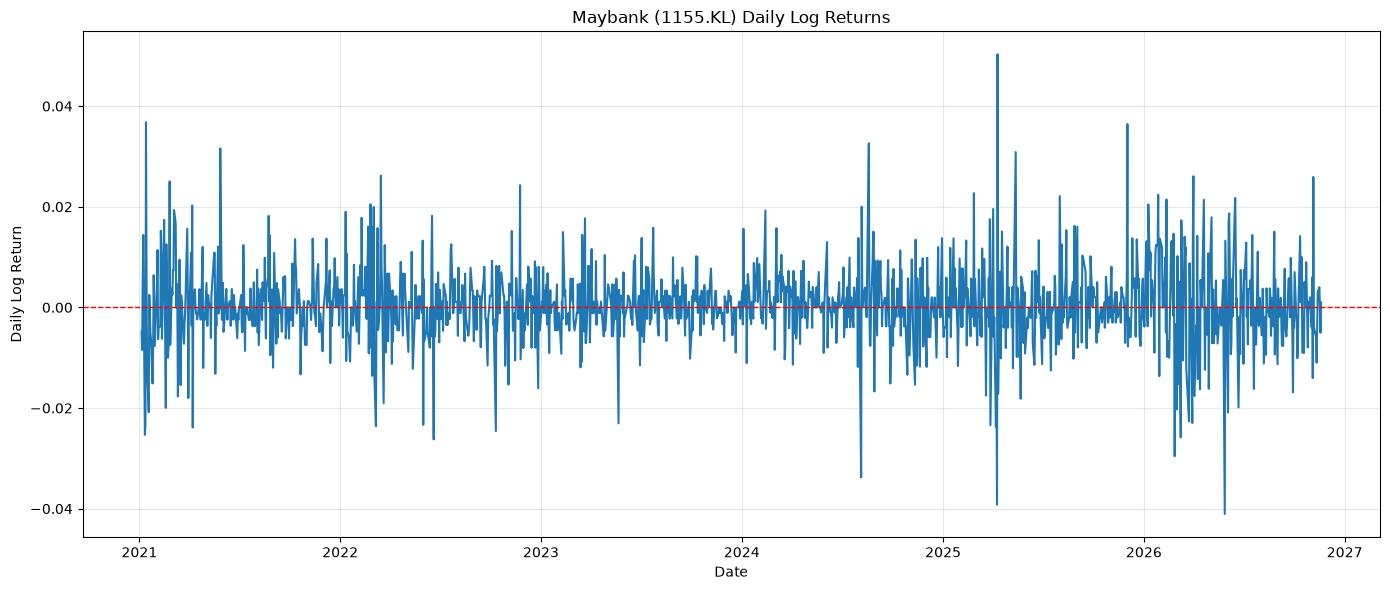

In [9]:

# Step 4.2: Visualise Daily Log Returns

import pandas as pd
import matplotlib.pyplot as plt

# Load processed Maybank data
maybank = pd.read_csv("data/processed/maybank_returns.csv")

# Convert Date column
maybank["Date"] = pd.to_datetime(maybank["Date"])

# Remove missing log returns
returns = maybank.dropna(subset=["log_return"])

# Create log return chart
plt.figure(figsize=(14, 6))

plt.plot(
    returns["Date"],
    returns["log_return"]
)

# Add zero reference line
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1
)

plt.title("Maybank (1155.KL) Daily Log Returns")
plt.xlabel("Date")
plt.ylabel("Daily Log Return")

plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    "outputs/figures/maybank_daily_log_returns.png",
    dpi=300
)

plt.show()


In [17]:

# Step 4.3: Augmented Dickey-Fuller (ADF) Test

import pandas as pd
from statsmodels.tsa.stattools import adfuller

# Load Maybank processed data
maybank = pd.read_csv("data/processed/maybank_returns.csv")

# Function to perform ADF test
def perform_adf_test(series, series_name):

    # Remove missing values
    series = series.dropna()

    # Perform ADF test
    result = adfuller(series, autolag="AIC")

    # Display results
    print("-----------------------------------")
    print("ADF Test:", series_name)
    print("-----------------------------------")

    print("ADF Statistic:", round(result[0], 6))
    print("P-value:", round(result[1], 6))
    print("Lags Used:", result[2])
    print("Observations:", result[3])

    print("\nCritical Values:")

    for key, value in result[4].items():
        print(key, ":", round(value, 6))

    # Interpret the result
    if result[1] < 0.05:
        print("\nConclusion: Stationary (Reject H0)")
    else:
        print("\nConclusion: Non-stationary evidence (Fail to reject H0)")


# Test closing price
perform_adf_test(
    maybank["Close"],
    "Maybank Closing Price"
)

# Test daily log returns
perform_adf_test(
    maybank["log_return"],
    "Maybank Daily Log Returns"
)


-----------------------------------
ADF Test: Maybank Closing Price
-----------------------------------
ADF Statistic: -1.522103
P-value: 0.52255
Lags Used: 11
Observations: 1427

Critical Values:
1% : -3.434941
5% : -2.863568
10% : -2.567849

Conclusion: Non-stationary evidence (Fail to reject H0)
-----------------------------------
ADF Test: Maybank Daily Log Returns
-----------------------------------
ADF Statistic: -19.266323
P-value: 0.0
Lags Used: 4
Observations: 1433

Critical Values:
1% : -3.434922
5% : -2.863559
10% : -2.567845

Conclusion: Stationary (Reject H0)


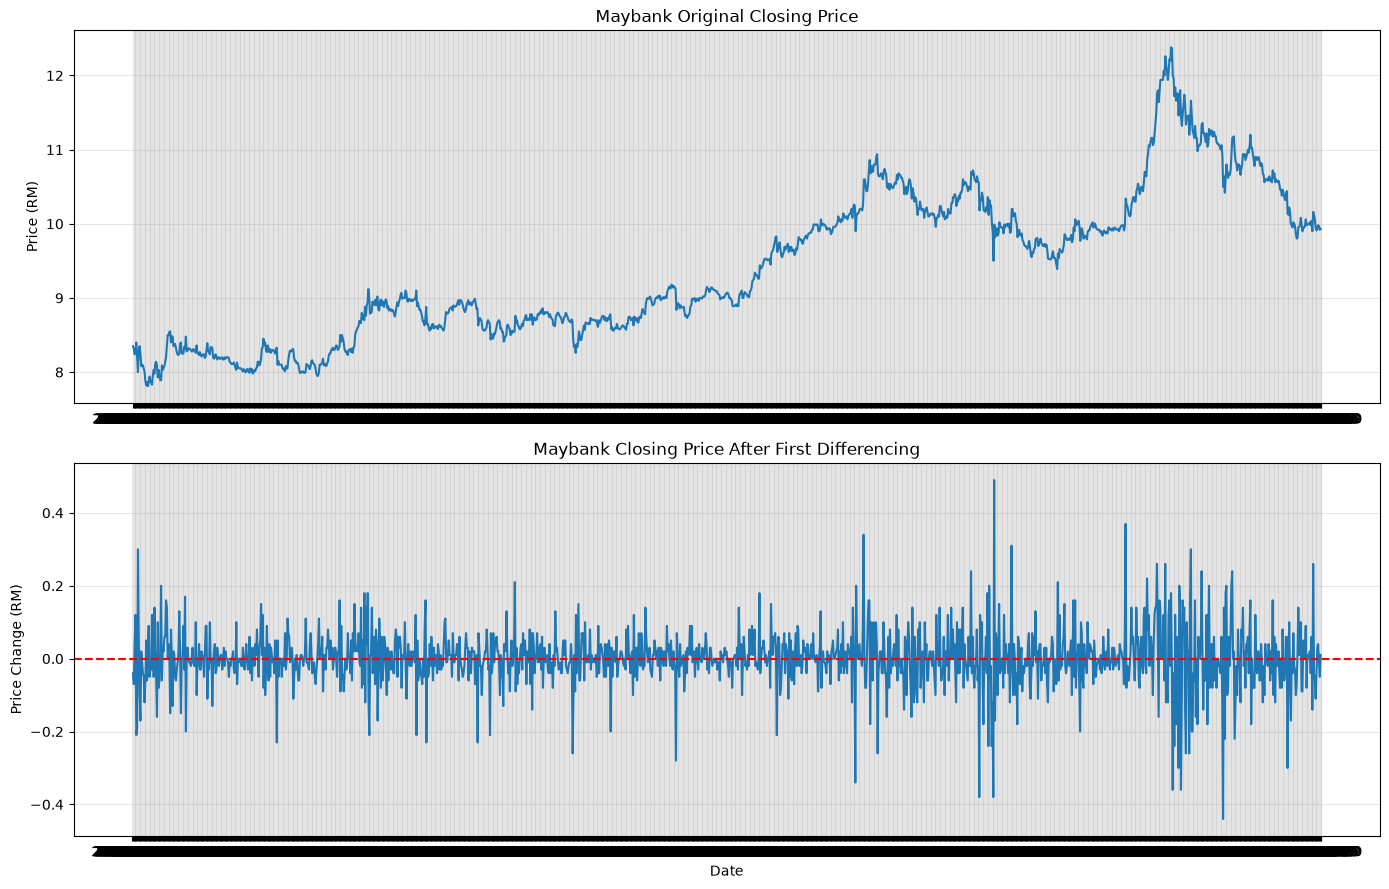

In [18]:

# Step 4.4: First Differencing

import pandas as pd
import matplotlib.pyplot as plt

# Load Maybank data
maybank = pd.read_csv("data/processed/maybank_returns.csv")

# Calculate first difference of closing price
maybank["Close_Diff"] = maybank["Close"].diff()

# Plot original closing price and differenced price
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Original closing price
axes[0].plot(maybank["Date"], maybank["Close"])
axes[0].set_title("Maybank Original Closing Price")
axes[0].set_ylabel("Price (RM)")
axes[0].grid(alpha=0.3)

# First differenced price
axes[1].plot(maybank["Date"], maybank["Close_Diff"])
axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_title("Maybank Closing Price After First Differencing")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Price Change (RM)")
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "outputs/figures/maybank_first_differencing.png",
    dpi=300
)

plt.show()


In [19]:

# Step 4.4: ADF Test After First Differencing

from statsmodels.tsa.stattools import adfuller

# Remove missing values
close_diff = maybank["Close_Diff"].dropna()

# Perform ADF test
adf_result = adfuller(close_diff, autolag="AIC")

# Display results
print("ADF Test After First Differencing")
print("-----------------------------------")

print("ADF Statistic:", round(adf_result[0], 6))
print("P-value:", round(adf_result[1], 6))

print("\nCritical Values:")

for key, value in adf_result[4].items():
    print(key, ":", round(value, 6))

# Conclusion
if adf_result[1] < 0.05:
    print("\nConclusion: Stationary (Reject H0)")
else:
    print("\nConclusion: Non-stationary evidence (Fail to reject H0)")


ADF Test After First Differencing
-----------------------------------
ADF Statistic: -11.286956
P-value: 0.0

Critical Values:
1% : -3.434941
5% : -2.863568
10% : -2.567849

Conclusion: Stationary (Reject H0)


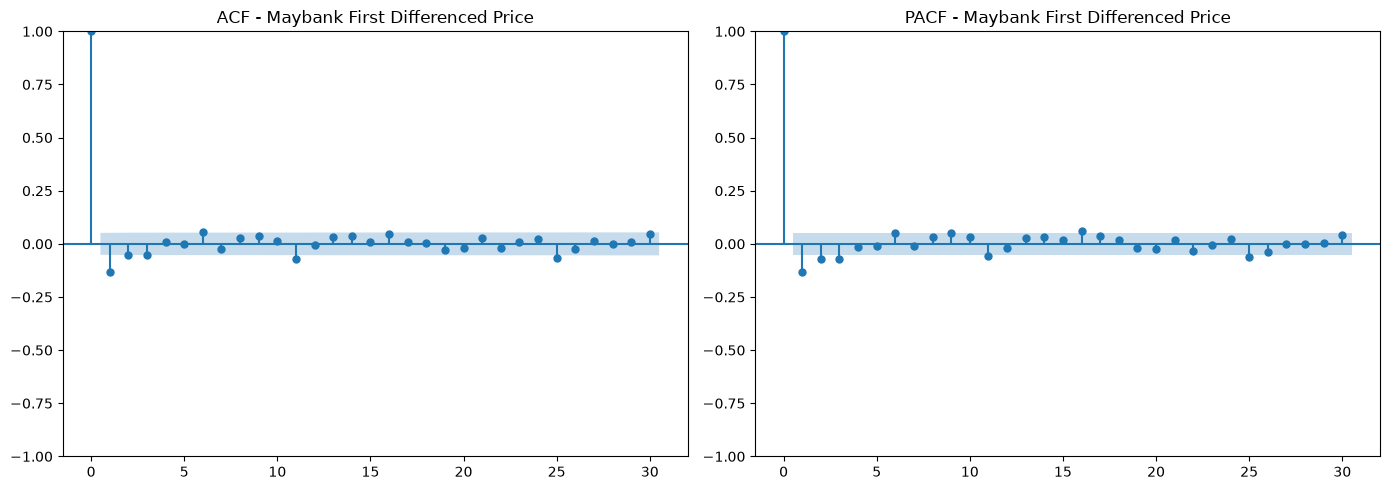

In [20]:

# Step 5: ACF and PACF Analysis

import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Load Maybank historical data
maybank = pd.read_csv("data/raw/maybank_1155_kl.csv")

# Calculate first difference of closing price
close_diff = maybank["Close"].diff().dropna()

# Create ACF and PACF plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ACF plot
plot_acf(
    close_diff,
    lags=30,
    ax=axes[0]
)

axes[0].set_title("ACF - Maybank First Differenced Price")

# PACF plot
plot_pacf(
    close_diff,
    lags=30,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF - Maybank First Differenced Price")

plt.tight_layout()

# Save charts
plt.savefig(
    "outputs/figures/maybank_acf_pacf.png",
    dpi=300
)

plt.show()


,Date,Close,log_close
0,2021-01-04,8.35,2.122262
1,2021-01-05,8.31,2.117460
2,2021-01-06,8.24,2.109000
3,2021-01-07,8.28,2.113843
4,2021-01-08,8.40,2.128232


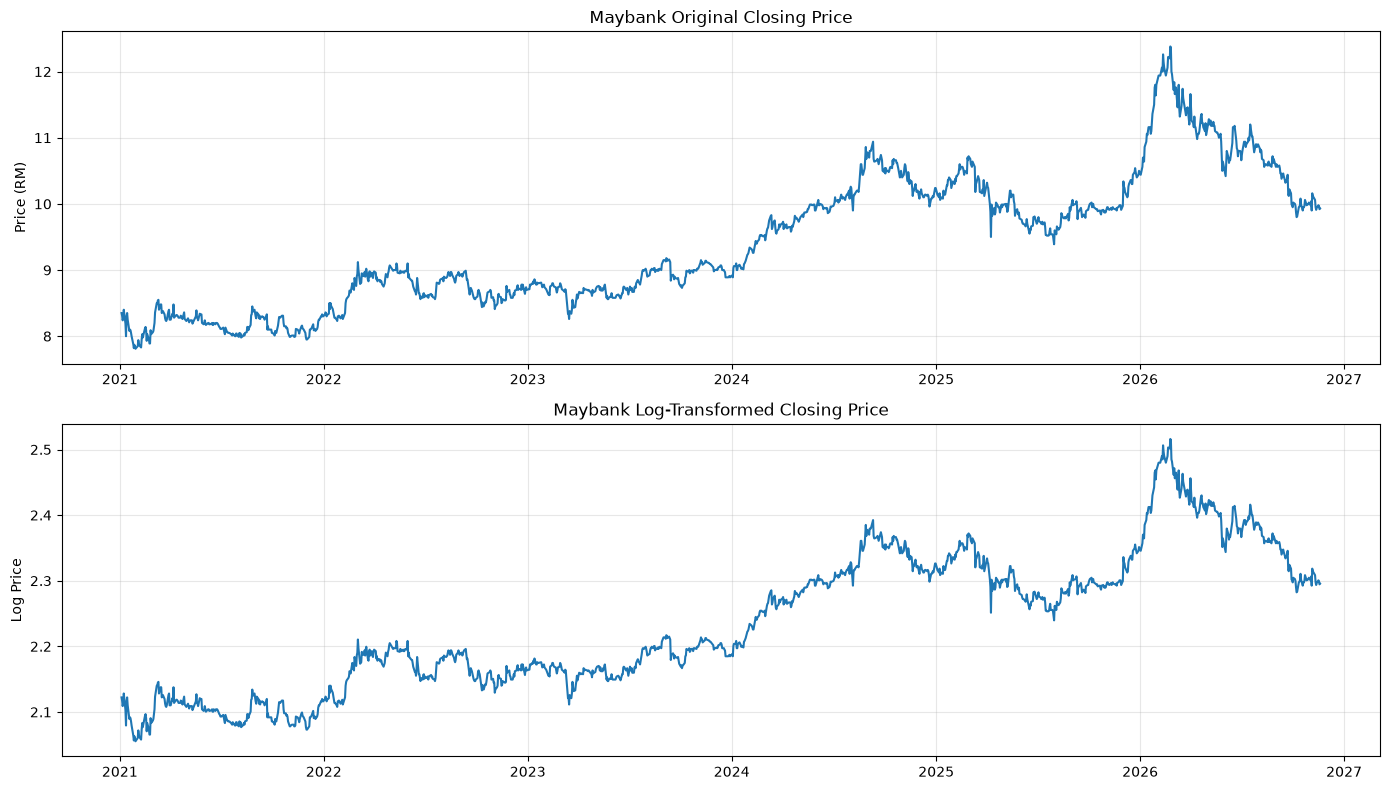

In [21]:

# Step 6.1: Log Transformation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Maybank data
maybank = pd.read_csv("data/raw/maybank_1155_kl.csv")

# Convert Date column
maybank["Date"] = pd.to_datetime(maybank["Date"])

# Sort data chronologically
maybank = maybank.sort_values("Date").reset_index(drop=True)

# Remove missing or invalid closing prices
maybank = maybank.dropna(subset=["Close"])
maybank = maybank[maybank["Close"] > 0].copy()

# Apply logarithmic transformation
maybank["log_close"] = np.log(maybank["Close"])

# Display original and transformed prices
display(
    maybank[["Date", "Close", "log_close"]].head()
)

# Plot both series
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(maybank["Date"], maybank["Close"])
axes[0].set_title("Maybank Original Closing Price")
axes[0].set_ylabel("Price (RM)")
axes[0].grid(alpha=0.3)

axes[1].plot(maybank["Date"], maybank["log_close"])
axes[1].set_title("Maybank Log-Transformed Closing Price")
axes[1].set_ylabel("Log Price")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [22]:

# Step 6.2: Split Training and Testing Data

# Calculate the 90% split position
split_point = int(len(maybank) * 0.90)

# Divide the dataset chronologically
train = maybank.iloc[:split_point].copy()
test = maybank.iloc[split_point:].copy()

# Extract log closing prices
train_data = train["log_close"]
test_data = test["log_close"]

# Display dataset information
print("Training Data:", len(train))
print("Testing Data:", len(test))

print("\nTraining Period:")
print(train["Date"].min(), "to", train["Date"].max())

print("\nTesting Period:")
print(test["Date"].min(), "to", test["Date"].max())


Training Data: 1295
Testing Data: 144

Training Period:
2021-01-04 00:00:00 to 2026-04-20 00:00:00

Testing Period:
2026-04-21 00:00:00 to 2026-11-19 00:00:00


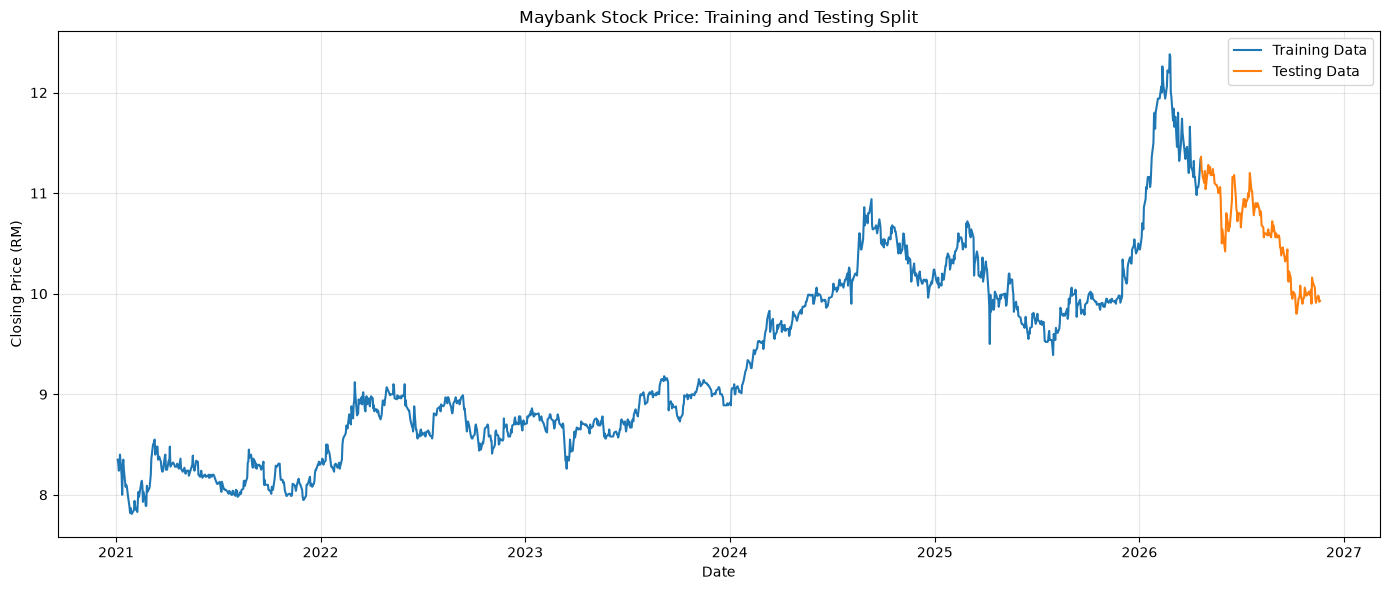

In [23]:

# Visualise Training and Testing Data

plt.figure(figsize=(14, 6))

plt.plot(
    train["Date"],
    train["Close"],
    label="Training Data"
)

plt.plot(
    test["Date"],
    test["Close"],
    label="Testing Data"
)

plt.title("Maybank Stock Price: Training and Testing Split")
plt.xlabel("Date")
plt.ylabel("Closing Price (RM)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/figures/maybank_train_test_split.png",
    dpi=300
)

plt.show()


ADF Test: Log-Transformed Price
ADF Statistic: -0.4088
P-value: 0.908619

ADF Test: First-Differenced Log Price
ADF Statistic: -24.33784
P-value: 0.0


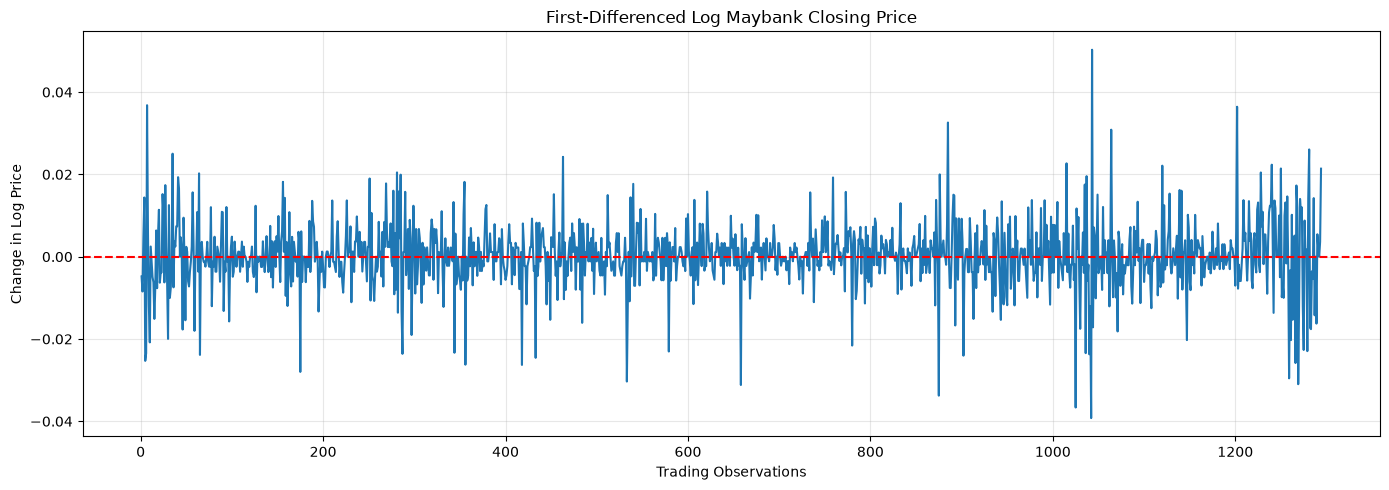

In [24]:

# Step 7.1: Determine the Differencing Order (d)

from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt

# Use training data only
log_price = train["log_close"].dropna()

# Apply first differencing
log_price_diff = log_price.diff().dropna()

# ADF test on log-transformed price
adf_level = adfuller(log_price, autolag="AIC")

# ADF test on first-differenced log price
adf_diff = adfuller(log_price_diff, autolag="AIC")

# Display results
print("ADF Test: Log-Transformed Price")
print("ADF Statistic:", round(adf_level[0], 6))
print("P-value:", round(adf_level[1], 6))

print("\nADF Test: First-Differenced Log Price")
print("ADF Statistic:", round(adf_diff[0], 6))
print("P-value:", round(adf_diff[1], 6))

# Plot the first-differenced log price
plt.figure(figsize=(14, 5))

plt.plot(log_price_diff)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("First-Differenced Log Maybank Closing Price")
plt.xlabel("Trading Observations")
plt.ylabel("Change in Log Price")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Selected differencing order (d): 1


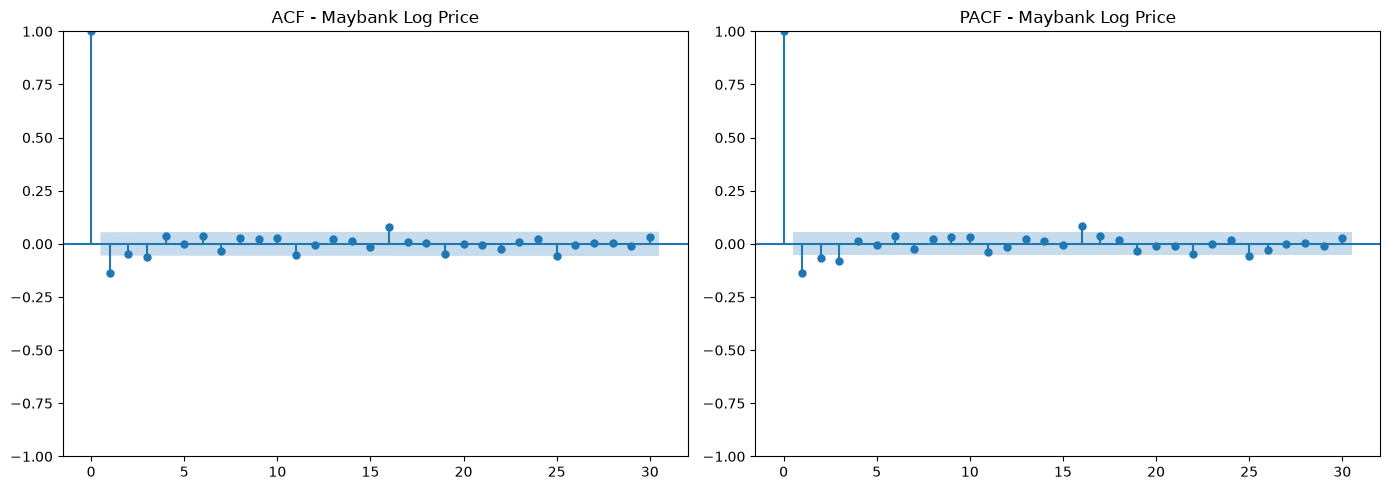

In [25]:

# Step 8.1: ACF and PACF Analysis

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# Use training data
log_price = train["log_close"].dropna()

# Determine differencing order
from statsmodels.tsa.stattools import adfuller

adf_level = adfuller(log_price, autolag="AIC")
adf_diff = adfuller(log_price.diff().dropna(), autolag="AIC")

if adf_level[1] < 0.05:
    d = 0
elif adf_diff[1] < 0.05:
    d = 1
else:
    raise ValueError(
        "First differencing is not sufficient. "
        "We need to investigate further before selecting d."
    )

print("Selected differencing order (d):", d)

# Prepare series for ACF and PACF
if d == 1:
    stationary_series = log_price.diff().dropna()
else:
    stationary_series = log_price

# Create ACF and PACF plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    stationary_series,
    lags=30,
    ax=axes[0]
)

axes[0].set_title("ACF - Maybank Log Price")

plot_pacf(
    stationary_series,
    lags=30,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF - Maybank Log Price")

plt.tight_layout()
plt.savefig(
    "outputs/figures/maybank_log_acf_pacf.png",
    dpi=300
)
plt.show()


In [26]:

# Step 8.2: Compare ARIMA Models Using AIC and BIC

import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

# Use training log price
model_data = train["log_close"].dropna()

# Candidate ARIMA models
candidate_orders = [
    (0, d, 0),
    (1, d, 0),
    (0, d, 1),
    (1, d, 1),
    (2, d, 1),
    (1, d, 2),
    (2, d, 2)
]

# Include Kaggle reference model if d = 1
if d == 1:
    candidate_orders.append((3, 1, 2))

# Store results
results = []

# Fit and compare models
for order in candidate_orders:

    try:
        model = ARIMA(model_data, order=order)
        fitted_model = model.fit()

        results.append({
            "ARIMA Order": str(order),
            "AIC": fitted_model.aic,
            "BIC": fitted_model.bic
        })

    except Exception as error:
        print("Model failed:", order, error)

# Create comparison table
comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    by="AIC"
).reset_index(drop=True)

print("ARIMA Model Comparison:")
display(comparison.round(2))


C:\Users\This Pc\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\This Pc\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


ARIMA Model Comparison:


,ARIMA Order,AIC,BIC
0,"(1, 1, 1)",-8877.22,-8861.72
1,"(3, 1, 2)",-8875.54,-8844.55
2,"(2, 1, 1)",-8875.38,-8854.72
3,"(1, 1, 2)",-8874.75,-8854.09
4,"(2, 1, 2)",-8874.17,-8848.34
5,"(0, 1, 1)",-8873.30,-8862.97
6,"(1, 1, 0)",-8869.56,-8859.23
7,"(0, 1, 0)",-8846.72,-8841.56


In [27]:

# Step 8.2: ARIMA Model Comparison with Convergence Check

import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

# Use training log price
model_data = train["log_close"].dropna()

# Candidate ARIMA models
candidate_orders = [
    (0, d, 0),
    (1, d, 0),
    (0, d, 1),
    (1, d, 1),
    (2, d, 1),
    (1, d, 2),
    (2, d, 2)
]

if d == 1:
    candidate_orders.append((3, 1, 2))

results = []

# Fit each candidate model
for order in candidate_orders:

    try:
        model = ARIMA(model_data, order=order)
        fitted_model = model.fit()

        results.append({
            "ARIMA Order": str(order),
            "AIC": fitted_model.aic,
            "BIC": fitted_model.bic,
            "Converged": fitted_model.mle_retvals.get(
                "converged", False
            )
        })

    except Exception as error:
        print("Model failed:", order, error)

# Display comparison
comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    by="AIC"
).reset_index(drop=True)

display(comparison.round(3))


C:\Users\This Pc\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\This Pc\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


,ARIMA Order,AIC,BIC,Converged
0,"(1, 1, 1)",-8877.215,-8861.719,True
1,"(3, 1, 2)",-8875.544,-8844.551,True
2,"(2, 1, 1)",-8875.385,-8854.723,True
3,"(1, 1, 2)",-8874.747,-8854.085,True
4,"(2, 1, 2)",-8874.171,-8848.344,True
5,"(0, 1, 1)",-8873.303,-8862.972,True
6,"(1, 1, 0)",-8869.561,-8859.230,True
7,"(0, 1, 0)",-8846.724,-8841.559,True


In [28]:

# Step 9.1: Select the Best ARIMA Model

# Keep models that successfully converged
valid_models = comparison[
    comparison["Converged"] == True
].copy()

# Check whether any models converged
if valid_models.empty:
    raise ValueError(
        "No candidate models converged. "
        "Please review the model comparison results."
    )

# Select model with the lowest AIC
best_model = valid_models.sort_values(
    by="AIC"
).iloc[0]

# Get the selected ARIMA order
import ast

selected_order = ast.literal_eval(
    best_model["ARIMA Order"]
)

print("Selected ARIMA Model:", selected_order)
print("AIC:", round(best_model["AIC"], 2))
print("BIC:", round(best_model["BIC"], 2))


Selected ARIMA Model: (1, 1, 1)
AIC: -8877.22
BIC: -8861.72


In [29]:

# Step 9.2: Fit the Selected ARIMA Model

from statsmodels.tsa.arima.model import ARIMA

# Fit the selected model
model = ARIMA(
    train["log_close"],
    order=selected_order
)

fitted_model = model.fit()

# Display model information
print("ARIMA Model:", selected_order)
print("Converged:", fitted_model.mle_retvals.get("converged"))
print("AIC:", round(fitted_model.aic, 2))
print("BIC:", round(fitted_model.bic, 2))

# Display statistical summary
print(fitted_model.summary())


ARIMA Model: (1, 1, 1)
Converged: True
AIC: -8877.22
BIC: -8861.72
                               SARIMAX Results                                
Dep. Variable:              log_close   No. Observations:                 1295
Model:                 ARIMA(1, 1, 1)   Log Likelihood                4441.608
Date:                Sat, 21 Nov 2026   AIC                          -8877.215
Time:                        02:27:27   BIC                          -8861.719
Sample:                             0   HQIC                         -8871.400
                               - 1295                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3403      0.118      2.887      0.004       0.109       0.571
ma.L1         -0.4955      0.108     -4.571      0.000      -0.7

In [30]:

# Step 10.1: Generate ARIMA Forecasts

import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

# Fit the selected ARIMA model
model = ARIMA(
    train["log_close"],
    order=selected_order
)

fitted_model = model.fit()

# Forecast the testing period
forecast_result = fitted_model.get_forecast(
    steps=len(test)
)

# Get forecasted log prices
forecast_log = forecast_result.predicted_mean

# Get 95% prediction intervals
forecast_interval = forecast_result.conf_int(alpha=0.05)

# Convert log prices back to actual RM prices
forecast_price = np.exp(np.asarray(forecast_log))

lower_price = np.exp(
    forecast_interval.iloc[:, 0].to_numpy()
)

upper_price = np.exp(
    forecast_interval.iloc[:, 1].to_numpy()
)

# Create forecast results table
forecast_table = pd.DataFrame({
    "Date": test["Date"].to_numpy(),
    "Actual Price": test["Close"].to_numpy(),
    "Forecast Price": forecast_price,
    "Lower 95%": lower_price,
    "Upper 95%": upper_price
})

# Display forecast results
display(forecast_table.head(10))


,Date,Actual Price,Forecast Price,Lower 95%,Upper 95%
0,2026-04-21,11.36,11.299297,11.127595,11.473649
1,2026-04-22,11.22,11.285480,11.061512,11.513983
2,2026-04-23,11.22,11.280782,11.019565,11.548191
3,2026-04-24,11.16,11.279183,10.986896,11.579247
4,2026-04-27,11.10,11.278640,10.958795,11.607819
5,2026-04-28,11.22,11.278454,10.933459,11.634336
6,2026-04-29,11.04,11.278392,10.910073,11.659144
7,2026-04-30,11.08,11.278370,10.888198,11.682524
8,2026-05-04,11.28,11.278363,10.867560,11.704694
9,2026-05-05,11.20,11.278360,10.847970,11.725826


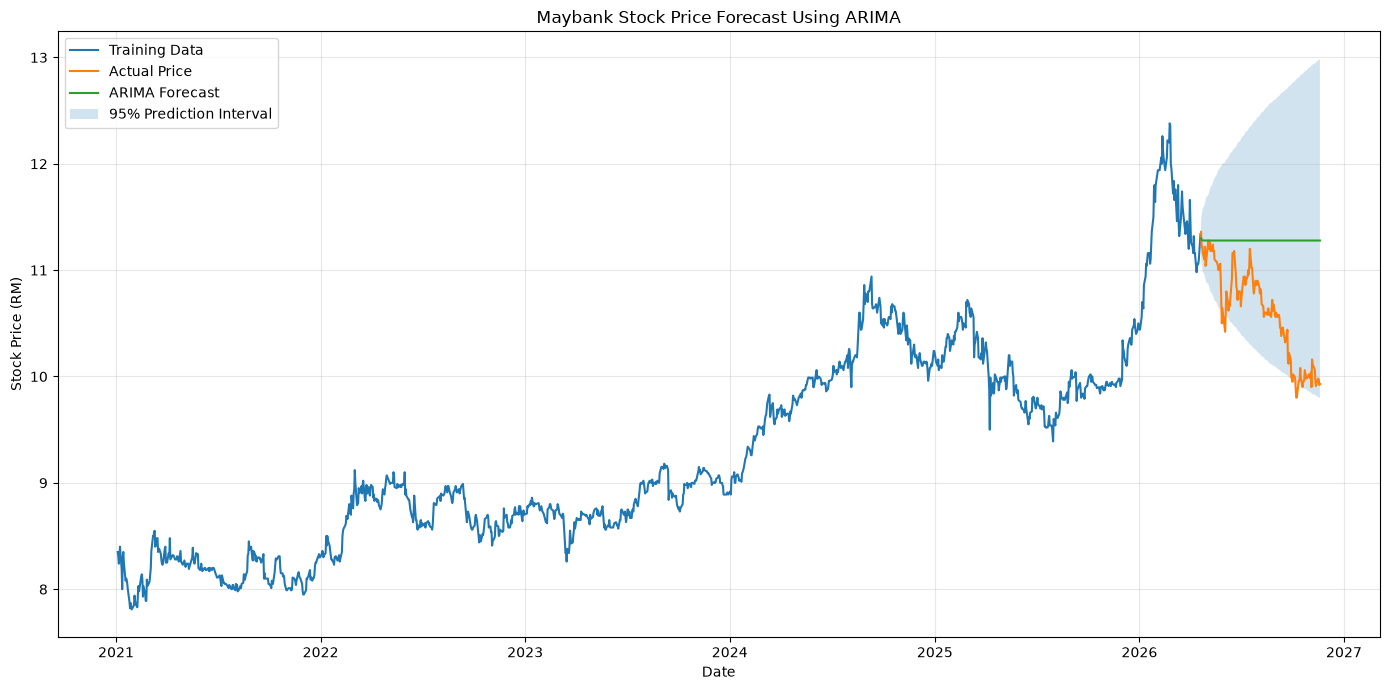

In [31]:

# Step 10.2: Plot Actual vs Predicted Stock Prices

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

# Training data
plt.plot(
    train["Date"],
    train["Close"],
    label="Training Data"
)

# Actual testing prices
plt.plot(
    test["Date"],
    test["Close"],
    label="Actual Price"
)

# ARIMA forecast
plt.plot(
    test["Date"],
    forecast_price,
    label="ARIMA Forecast"
)

# 95% prediction interval
plt.fill_between(
    test["Date"],
    lower_price,
    upper_price,
    alpha=0.2,
    label="95% Prediction Interval"
)

plt.title("Maybank Stock Price Forecast Using ARIMA")
plt.xlabel("Date")
plt.ylabel("Stock Price (RM)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    "outputs/figures/maybank_arima_forecast.png",
    dpi=300
)

plt.show()


In [32]:

# Step 10.3: Save Forecast Results

forecast_table.to_csv(
    "outputs/maybank_arima_test_forecast.csv",
    index=False
)

print("Forecast results saved successfully!")

display(forecast_table.head())


Forecast results saved successfully!


,Date,Actual Price,Forecast Price,Lower 95%,Upper 95%
0,2026-04-21,11.36,11.299297,11.127595,11.473649
1,2026-04-22,11.22,11.285480,11.061512,11.513983
2,2026-04-23,11.22,11.280782,11.019565,11.548191
3,2026-04-24,11.16,11.279183,10.986896,11.579247
4,2026-04-27,11.10,11.278640,10.958795,11.607819


In [33]:

# Step 11.1: Evaluate ARIMA Forecasting Performance

import numpy as np
import pandas as pd

# Get actual and forecasted prices
actual = forecast_table["Actual Price"].to_numpy()
predicted = forecast_table["Forecast Price"].to_numpy()

# Calculate forecasting errors
errors = actual - predicted

# Calculate evaluation metrics
mae = np.mean(np.abs(errors))

mse = np.mean(errors ** 2)

rmse = np.sqrt(mse)

mape = np.mean(
    np.abs(errors / actual)
) * 100

# Display results
print("ARIMA Forecasting Performance")
print("--------------------------------")

print("MAE  :", round(mae, 4))
print("MSE  :", round(mse, 4))
print("RMSE :", round(rmse, 4))
print("MAPE :", round(mape, 2), "%")


ARIMA Forecasting Performance
--------------------------------
MAE  : 0.6862
MSE  : 0.6624
RMSE : 0.8139
MAPE : 6.66 %


In [34]:

# Step 11.2: Random Walk Benchmark

# Last observed training-period closing price
last_train_price = train["Close"].iloc[-1]

# Predict the same price throughout the testing period
random_walk_prediction = np.repeat(
    last_train_price,
    len(test)
)

# Calculate benchmark forecasting errors
random_walk_errors = test["Close"].to_numpy() - random_walk_prediction

rw_mae = np.mean(np.abs(random_walk_errors))

rw_mse = np.mean(random_walk_errors ** 2)

rw_rmse = np.sqrt(rw_mse)

rw_mape = np.mean(
    np.abs(random_walk_errors / test["Close"].to_numpy())
) * 100

print("Random Walk Forecasting Performance")
print("------------------------------------")

print("MAE  :", round(rw_mae, 4))
print("MSE  :", round(rw_mse, 4))
print("RMSE :", round(rw_rmse, 4))
print("MAPE :", round(rw_mape, 2), "%")


Random Walk Forecasting Performance
------------------------------------
MAE  : 0.747
MSE  : 0.7507
RMSE : 0.8664
MAPE : 7.24 %


In [35]:

# Step 11.3: Compare ARIMA and Random Walk

performance = pd.DataFrame({
    "Evaluation Metric": ["MAE", "MSE", "RMSE", "MAPE"],
    "ARIMA": [mae, mse, rmse, mape],
    "Random Walk": [rw_mae, rw_mse, rw_rmse, rw_mape]
})

print("Model Performance Comparison")

display(performance.round(4))

# Save comparison results
performance.to_csv(
    "outputs/maybank_model_comparison.csv",
    index=False
)


Model Performance Comparison


,Evaluation Metric,ARIMA,Random Walk
0,MAE,0.6862,0.7470
1,MSE,0.6624,0.7507
2,RMSE,0.8139,0.8664
3,MAPE,6.6626,7.2384


In [36]:

# Step 12.1: Fit Final ARIMA Model Using All Available Data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA

# Load complete Maybank dataset
maybank_full = pd.read_csv("data/raw/maybank_1155_kl.csv")

# Prepare data
maybank_full["Date"] = pd.to_datetime(maybank_full["Date"])

maybank_full = maybank_full.sort_values(
    "Date"
).reset_index(drop=True)

maybank_full = maybank_full.dropna(
    subset=["Close"]
).copy()

# Create log closing price
maybank_full["log_close"] = np.log(
    maybank_full["Close"]
)

# Fit the selected ARIMA model using all observations
final_model = ARIMA(
    maybank_full["log_close"],
    order=selected_order
).fit()

print("Final ARIMA Model:", selected_order)
print("Model Converged:",
      final_model.mle_retvals.get("converged"))

print("Latest Available Price:",
      maybank_full["Close"].iloc[-1])


Final ARIMA Model: (1, 1, 1)
Model Converged: True
Latest Available Price: 9.93000030517578


In [37]:

# Step 12.2: Forecast the Next 30 Trading Observations

# Set forecast horizon
forecast_days = 30

# Generate future forecasts
future_result = final_model.get_forecast(
    steps=forecast_days
)

# Get predicted log prices
future_log_forecast = future_result.predicted_mean

# Get 95% prediction intervals
future_intervals = future_result.conf_int(alpha=0.05)

# Convert log prices into RM prices
future_prices = np.exp(
    np.asarray(future_log_forecast)
)

lower_bounds = np.exp(
    future_intervals.iloc[:, 0].to_numpy()
)

upper_bounds = np.exp(
    future_intervals.iloc[:, 1].to_numpy()
)

# Create forecast results table
future_forecast_table = pd.DataFrame({
    "Forecast Step": range(1, forecast_days + 1),
    "Forecast Price (RM)": future_prices,
    "Lower 95% (RM)": lower_bounds,
    "Upper 95% (RM)": upper_bounds
})

# Display results
display(future_forecast_table.head(10))


,Forecast Step,Forecast Price (RM),Lower 95% (RM),Upper 95% (RM)
0,1,9.932900,9.779610,10.088592
1,2,9.934201,9.733373,10.139172
2,3,9.934784,9.701245,10.173946
3,4,9.935046,9.675001,10.202081
4,5,9.935164,9.651977,10.226660
5,6,9.935217,9.631047,10.248993
6,7,9.935240,9.611645,10.269731
7,8,9.935251,9.593442,10.289238
8,9,9.935256,9.576229,10.307743
9,10,9.935258,9.559854,10.325403


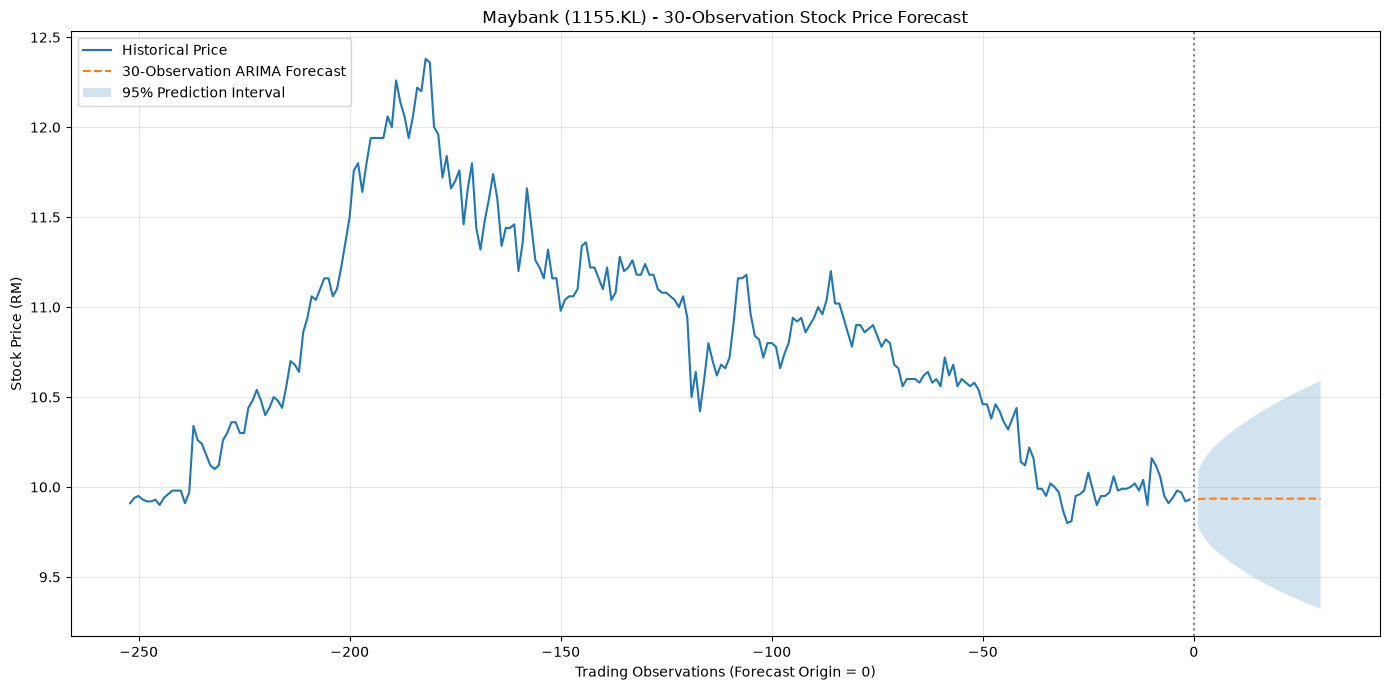

In [38]:

# Step 12.3: Plot Future Maybank Stock Price Forecast

# Select the latest 252 historical observations
historical = maybank_full.tail(252)

# Create horizontal axis based on trading observations
history_x = np.arange(-len(historical), 0)

future_x = np.arange(1, forecast_days + 1)

plt.figure(figsize=(14, 7))

# Historical stock prices
plt.plot(
    history_x,
    historical["Close"],
    label="Historical Price"
)

# Forecasted prices
plt.plot(
    future_x,
    future_prices,
    label="30-Observation ARIMA Forecast",
    linestyle="--"
)

# 95% prediction interval
plt.fill_between(
    future_x,
    lower_bounds,
    upper_bounds,
    alpha=0.2,
    label="95% Prediction Interval"
)

# Forecast starting point
plt.axvline(
    x=0,
    color="gray",
    linestyle=":"
)

plt.title(
    "Maybank (1155.KL) - 30-Observation Stock Price Forecast"
)

plt.xlabel("Trading Observations (Forecast Origin = 0)")
plt.ylabel("Stock Price (RM)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    "outputs/figures/maybank_30_day_forecast.png",
    dpi=300
)

plt.show()


In [39]:

# Step 12.4: Save Future Forecast Results

future_forecast_table.to_csv(
    "outputs/maybank_30_day_forecast.csv",
    index=False
)

print("Future forecast saved successfully!")

print("\nForecast summary:")

print(
    "First forecast:",
    round(future_prices[0], 4),
    "RM"
)

print(
    "30th forecast:",
    round(future_prices[-1], 4),
    "RM"
)


Future forecast saved successfully!

Forecast summary:
First forecast: 9.9329 RM
30th forecast: 9.9353 RM


In [40]:

# Step 13.1: Extract ARIMA Residuals

import pandas as pd
import numpy as np

# Extract residuals from the training model
residuals = pd.Series(
    fitted_model.resid
).dropna().reset_index(drop=True)

# Display residual information
print("ARIMA Residual Analysis")
print("------------------------")

print("Residual Mean:", round(residuals.mean(), 6))
print("Residual Standard Deviation:", round(residuals.std(), 6))

print("\nFirst five residuals:")
display(residuals.head())


ARIMA Residual Analysis
------------------------
Residual Mean: 0.001943
Residual Standard Deviation: 0.059481

First five residuals:


0    2.122262
1   -0.004802
2   -0.009142
3    0.003221
4    0.014334
dtype: float64

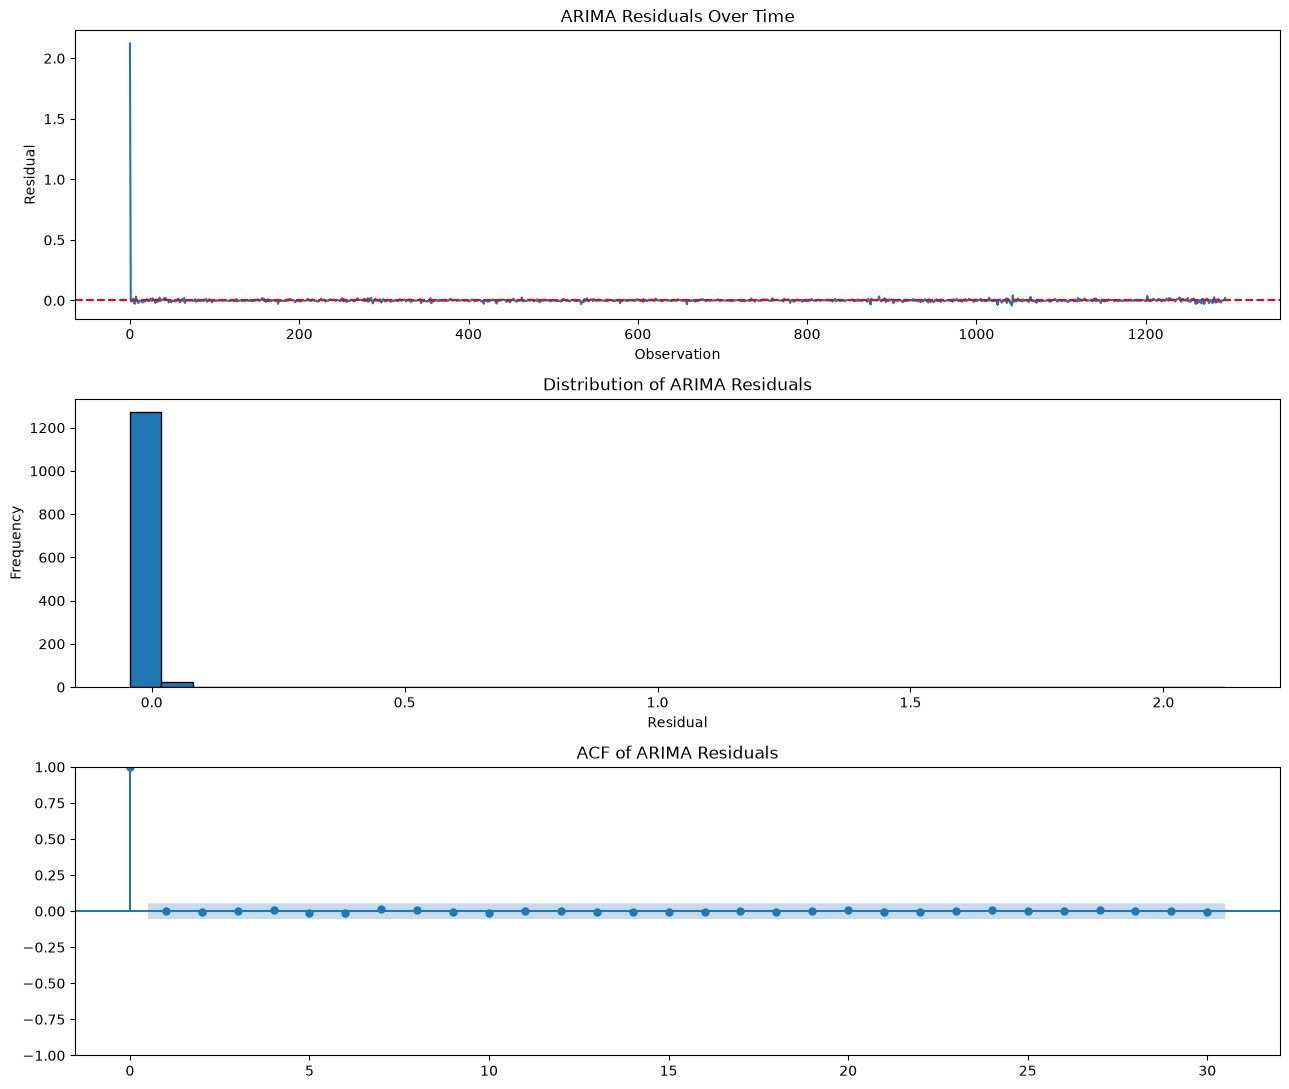

In [41]:

# Step 13.2: Visualise ARIMA Residuals

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(3, 1, figsize=(13, 11))

# Plot 1: Residuals over time
axes[0].plot(residuals)
axes[0].axhline(y=0, color="red", linestyle="--")

axes[0].set_title("ARIMA Residuals Over Time")
axes[0].set_xlabel("Observation")
axes[0].set_ylabel("Residual")

# Plot 2: Residual distribution
axes[1].hist(
    residuals,
    bins=35,
    edgecolor="black"
)

axes[1].set_title("Distribution of ARIMA Residuals")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")

# Plot 3: Residual ACF
plot_acf(
    residuals,
    lags=30,
    ax=axes[2]
)

axes[2].set_title("ACF of ARIMA Residuals")

plt.tight_layout()

# Save diagnostic chart
plt.savefig(
    "outputs/figures/maybank_arima_residuals.png",
    dpi=300
)

plt.show()


In [42]:

# Step 13.3: Ljung-Box Test

from statsmodels.stats.diagnostic import acorr_ljungbox

# Account for AR and MA parameters
model_df = selected_order[0] + selected_order[2]

# Perform Ljung-Box test
ljung_box = acorr_ljungbox(
    residuals,
    lags=[10, 20],
    model_df=model_df,
    return_df=True
)

# Display results
print("Ljung-Box Test Results")
display(ljung_box.round(4))

# Interpret p-values
for lag, result in ljung_box.iterrows():

    p_value = result["lb_pvalue"]

    print(f"\nLag {lag}: P-value = {p_value:.4f}")

    if p_value < 0.05:
        print("Residual autocorrelation may remain.")
    else:
        print("No significant residual autocorrelation detected.")


Ljung-Box Test Results


,lb_stat,lb_pvalue
10,0.8599,0.999
20,1.0429,1.000



Lag 10: P-value = 0.9990
No significant residual autocorrelation detected.

Lag 20: P-value = 1.0000
No significant residual autocorrelation detected.


In [43]:

# Step 14: Maybank Financial Risk Analysis

import pandas as pd
import numpy as np

# Load Maybank historical data
maybank = pd.read_csv(
    "data/raw/maybank_1155_kl.csv"
)

# Prepare the data
maybank["Date"] = pd.to_datetime(maybank["Date"])

maybank = maybank.sort_values(
    "Date"
).reset_index(drop=True)

# Use Adjusted Close for financial return analysis
maybank = maybank.dropna(
    subset=["Adj Close"]
).copy()

# Calculate adjusted daily returns
maybank["simple_return"] = (
    maybank["Adj Close"].pct_change()
)

maybank["log_return"] = np.log(
    maybank["Adj Close"] /
    maybank["Adj Close"].shift(1)
)

# Remove first missing return
returns = maybank.dropna(
    subset=["simple_return", "log_return"]
)

# 1. Daily return statistics
mean_daily = returns["log_return"].mean()

daily_volatility = returns["log_return"].std()

# 2. Annualised return
annualised_log_return = mean_daily * 252

annualised_compounded_return = (
    np.exp(annualised_log_return) - 1
)

# 3. Annualised volatility
annualised_volatility = (
    daily_volatility * np.sqrt(252)
)

# 4. Historical VaR (95%)
var_threshold = np.percentile(
    returns["simple_return"], 5
)

historical_var = -var_threshold

# 5. Conditional VaR / Expected Shortfall (95%)
tail_returns = returns.loc[
    returns["simple_return"] <= var_threshold,
    "simple_return"
]

cvar = -tail_returns.mean()

# 6. Maximum Drawdown
maybank["running_peak"] = (
    maybank["Adj Close"].cummax()
)

maybank["drawdown"] = (
    maybank["Adj Close"] /
    maybank["running_peak"] - 1
)

maximum_drawdown = maybank["drawdown"].min()

# Display results
print("MAYBANK FINANCIAL RISK ANALYSIS")
print("================================")

print(
    f"Daily Mean Log Return: {mean_daily * 100:.4f}%"
)

print(
    f"Annualised Average Log Return: "
    f"{annualised_log_return * 100:.2f}%"
)

print(
    f"Annualised Compounded Equivalent: "
    f"{annualised_compounded_return * 100:.2f}%"
)

print(
    f"Annualised Volatility: "
    f"{annualised_volatility * 100:.2f}%"
)

print(
    f"Historical VaR (95%): "
    f"{historical_var * 100:.2f}%"
)

print(
    f"Historical CVaR (95%): "
    f"{cvar * 100:.2f}%"
)

print(
    f"Maximum Drawdown: "
    f"{maximum_drawdown * 100:.2f}%"
)


MAYBANK FINANCIAL RISK ANALYSIS
Daily Mean Log Return: 0.0394%
Annualised Average Log Return: 9.94%
Annualised Compounded Equivalent: 10.45%
Annualised Volatility: 12.32%
Historical VaR (95%): 1.12%
Historical CVaR (95%): 1.73%
Maximum Drawdown: -16.07%


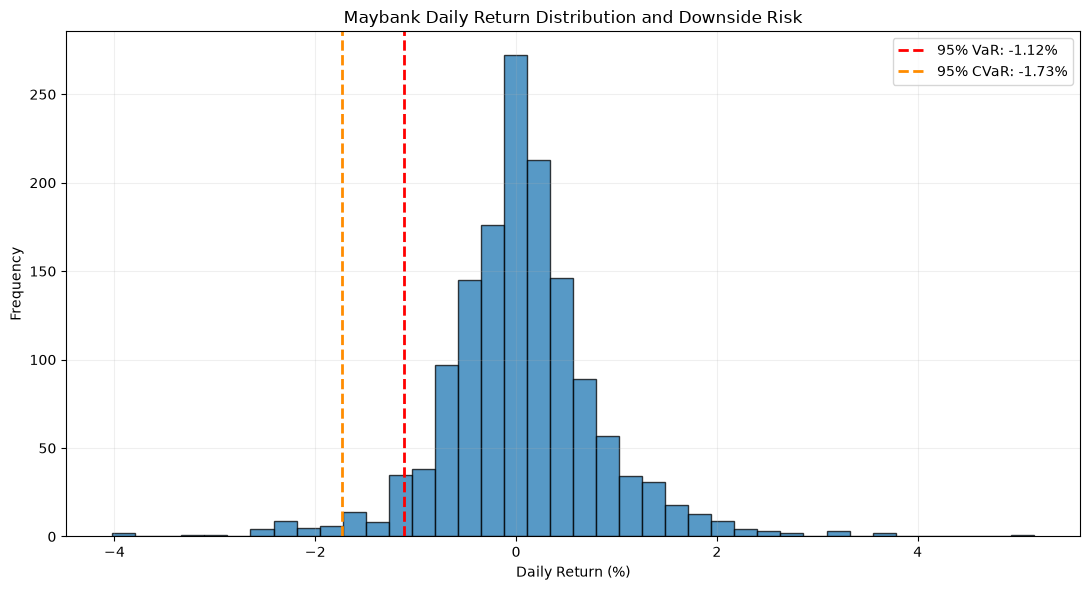

In [44]:

# Step 14.8: Daily Return Distribution and VaR

import matplotlib.pyplot as plt
import os

plt.figure(figsize=(11, 6))

# Plot daily return distribution
plt.hist(
    returns["simple_return"] * 100,
    bins=40,
    edgecolor="black",
    alpha=0.75
)

# VaR threshold
plt.axvline(
    var_threshold * 100,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"95% VaR: {-historical_var * 100:.2f}%"
)

# CVaR threshold
plt.axvline(
    -cvar * 100,
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label=f"95% CVaR: {-cvar * 100:.2f}%"
)

plt.title(
    "Maybank Daily Return Distribution and Downside Risk"
)

plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "outputs/figures/maybank_return_distribution.png",
    dpi=300
)

plt.show()


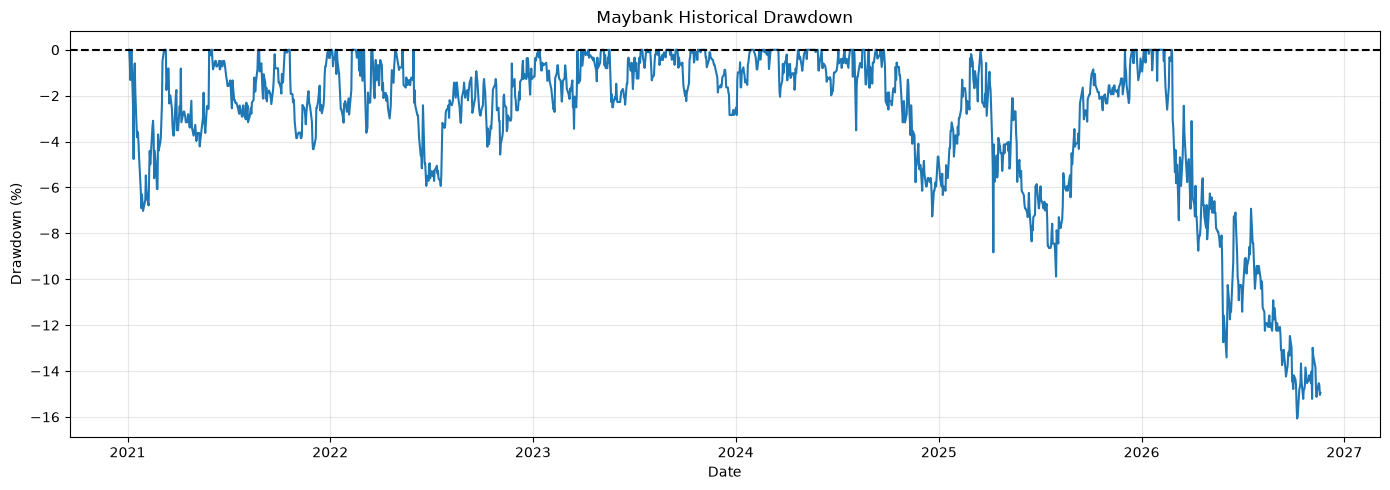

In [45]:

# Step 14.9: Maximum Drawdown Chart

plt.figure(figsize=(14, 5))

plt.plot(
    maybank["Date"],
    maybank["drawdown"] * 100
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--"
)

plt.title("Maybank Historical Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/figures/maybank_drawdown.png",
    dpi=300
)

plt.show()


In [46]:

# Step 14.10: Save Financial Risk Summary

risk_summary = pd.DataFrame({
    "Metric": [
        "Annualised Average Log Return",
        "Annualised Compounded Equivalent",
        "Annualised Volatility",
        "Historical VaR (95%)",
        "Historical CVaR (95%)",
        "Maximum Drawdown"
    ],
    "Value (%)": [
        annualised_log_return * 100,
        annualised_compounded_return * 100,
        annualised_volatility * 100,
        historical_var * 100,
        cvar * 100,
        -maximum_drawdown * 100
    ]
})

risk_summary.to_csv(
    "outputs/maybank_risk_summary.csv",
    index=False
)

display(risk_summary.round(2))

print("Risk analysis results saved successfully!")


,Metric,Value (%)
0,Annualised Average Log Return,9.94
1,Annualised Compounded Equivalent,10.45
2,Annualised Volatility,12.32
3,Historical VaR (95%),1.12
4,Historical CVaR (95%),1.73
5,Maximum Drawdown,16.07


Risk analysis results saved successfully!


In [47]:

# Step 15: Monte Carlo Simulation

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load Maybank processed data
df = pd.read_csv(
    "data/processed/maybank_returns.csv"
)

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

# Historical daily log returns
returns = df["log_return"].dropna()

# Latest adjusted closing price
last_price = df["Adj Close"].dropna().iloc[-1]

last_date = df["Date"].iloc[-1]

# 2. Calculate historical mean and volatility
mu = returns.mean()

sigma = returns.std()

print("Historical Daily Mean Return:", round(mu, 6))
print("Historical Daily Volatility:", round(sigma, 6))

# 3. Set simulation parameters
np.random.seed(42)

n_sims = 500
n_days = 30

# 4. Generate random daily log returns
sim_log_returns = np.random.normal(
    loc=mu,
    scale=sigma,
    size=(n_days, n_sims)
)

# 5. Convert simulated returns into prices
sim_prices = np.vstack([
    np.full((1, n_sims), last_price),
    last_price * np.exp(
        np.cumsum(sim_log_returns, axis=0)
    )
])

# 6. Analyse prices after 30 trading days
day30_prices = sim_prices[-1]

median_30d = np.median(day30_prices)

p05_30d = np.percentile(day30_prices, 5)

p95_30d = np.percentile(day30_prices, 95)

# Display results
print("\nMONTE CARLO SIMULATION RESULTS")
print("--------------------------------")

print("Starting Adj Close:", last_date.date())
print(f"Starting Price: RM {last_price:.2f}")

print(
    f"30-Day Median Simulated Price: RM {median_30d:.2f}"
)

print(
    f"30-Day 5th Percentile: RM {p05_30d:.2f}"
)

print(
    f"30-Day 95th Percentile: RM {p95_30d:.2f}"
)


Historical Daily Mean Return: 0.000394
Historical Daily Volatility: 0.007761

MONTE CARLO SIMULATION RESULTS
--------------------------------
Starting Adj Close: 2026-11-20
Starting Price: RM 9.93
30-Day Median Simulated Price: RM 10.05
30-Day 5th Percentile: RM 9.42
30-Day 95th Percentile: RM 10.75


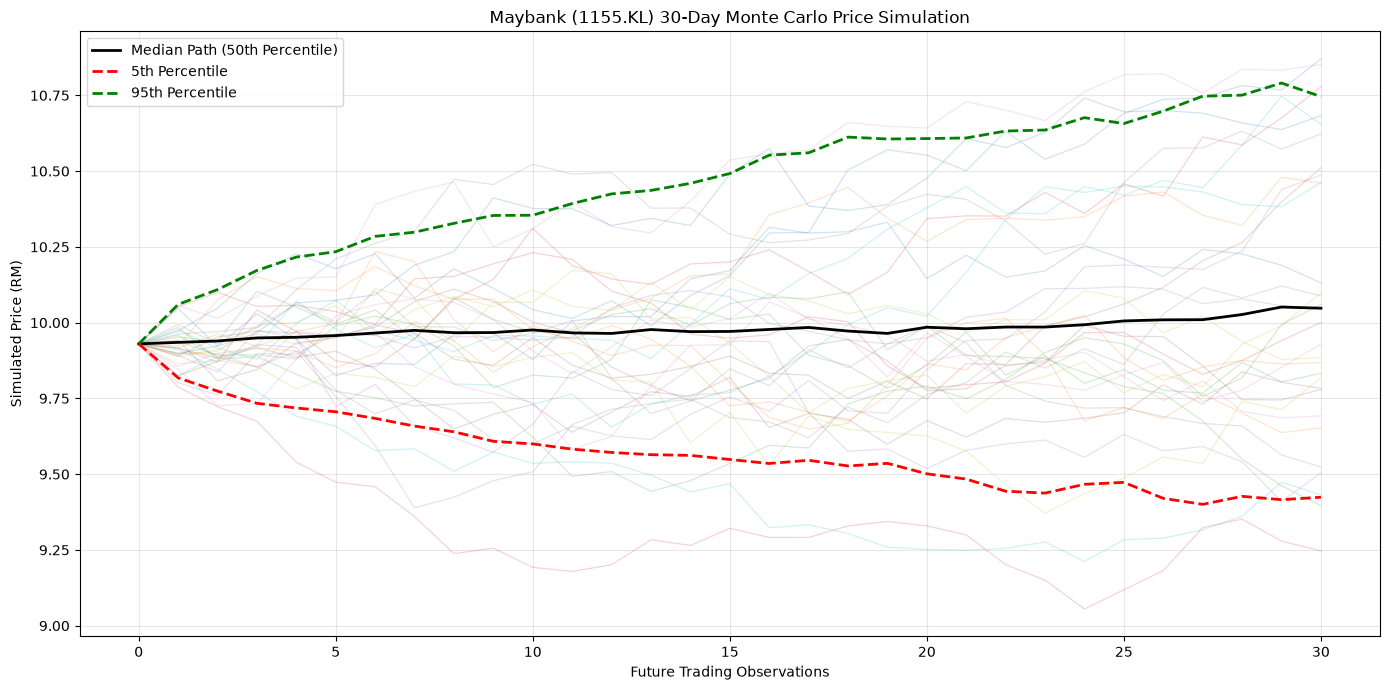

In [48]:

# Step 15.5: Visualise Monte Carlo Simulation

# Create trading observation numbers
future_steps = np.arange(n_days + 1)

# Calculate percentiles for every simulated day
median_path = np.median(sim_prices, axis=1)

p05_path = np.percentile(
    sim_prices, 5, axis=1
)

p95_path = np.percentile(
    sim_prices, 95, axis=1
)

# Create chart
plt.figure(figsize=(14, 7))

# Plot 30 sample simulation paths
plt.plot(
    future_steps,
    sim_prices[:, :30],
    alpha=0.2,
    linewidth=0.9
)

# Plot median path
plt.plot(
    future_steps,
    median_path,
    color="black",
    linewidth=2,
    label="Median Path (50th Percentile)"
)

# Plot 5th percentile
plt.plot(
    future_steps,
    p05_path,
    color="red",
    linestyle="--",
    linewidth=2,
    label="5th Percentile"
)

# Plot 95th percentile
plt.plot(
    future_steps,
    p95_path,
    color="green",
    linestyle="--",
    linewidth=2,
    label="95th Percentile"
)

plt.title(
    "Maybank (1155.KL) 30-Day Monte Carlo Price Simulation"
)

plt.xlabel("Future Trading Observations")
plt.ylabel("Simulated Price (RM)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
os.makedirs("outputs/figures", exist_ok=True)

plt.savefig(
    "outputs/figures/maybank_monte_carlo_30d.png",
    dpi=300
)

plt.show()


In [49]:

# Step 15.6: Save Monte Carlo Results

simulation_results = pd.DataFrame({
    "Simulation": range(1, n_sims + 1),
    "Day_30_Price": day30_prices
})

simulation_results.to_csv(
    "outputs/maybank_monte_carlo_results.csv",
    index=False
)

print("Monte Carlo results saved successfully!")

display(simulation_results.head())


Monte Carlo results saved successfully!


,Simulation,Day_30_Price
0,1,10.870452
1,2,9.868533
2,3,10.059817
3,4,10.000275
4,5,10.487237


Corrected Residual Mean: 0.000304
Corrected Residual Std: 0.007814


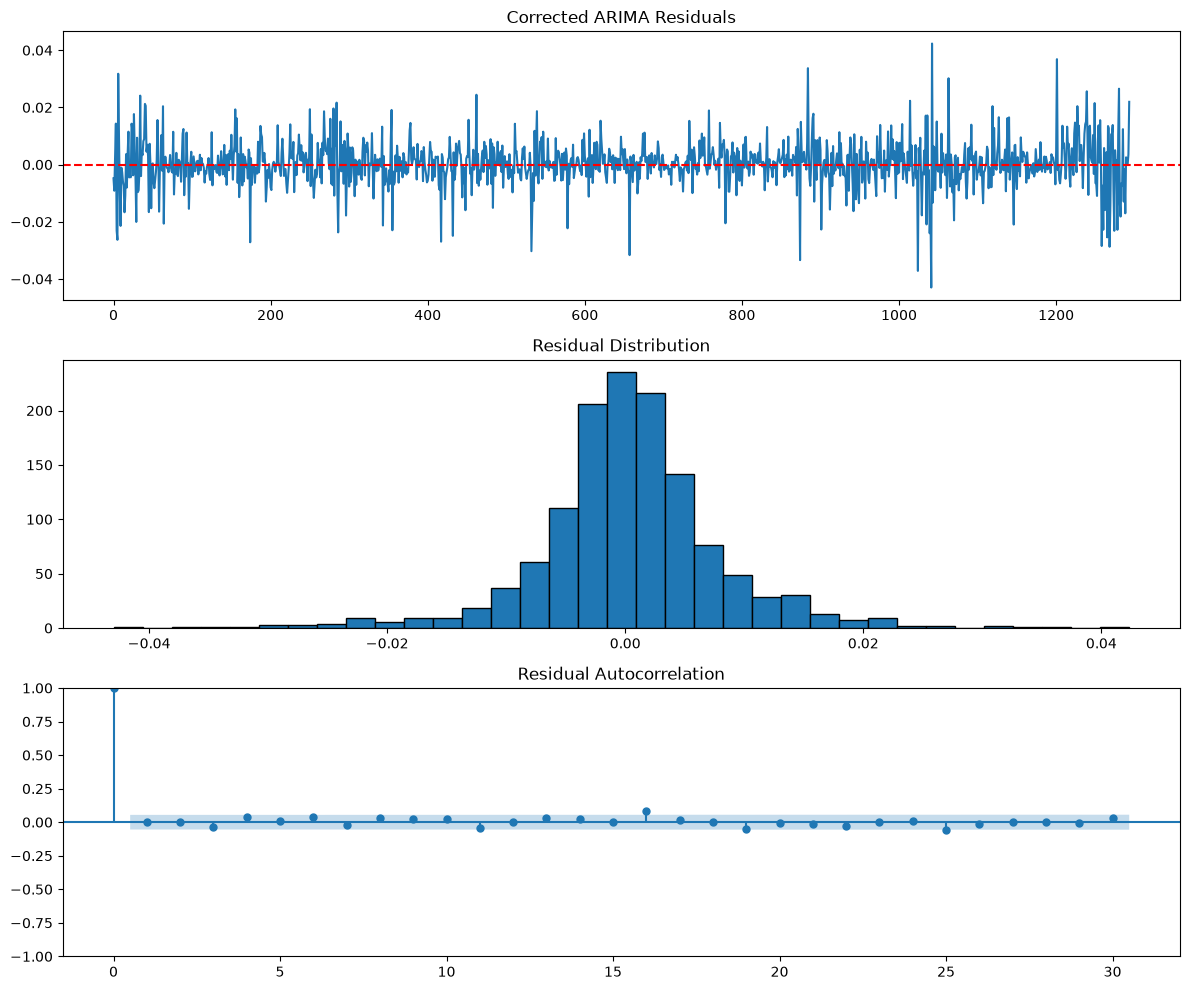

,lb_stat,lb_pvalue
10,9.768805,0.281629
20,27.198713,0.075343


In [50]:

# Corrected ARIMA Residual Diagnostics

import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Exclude the first initialization-affected residual
residuals_clean = pd.Series(
    fitted_model.resid
).iloc[1:].dropna().reset_index(drop=True)

print("Corrected Residual Mean:",
      round(residuals_clean.mean(), 6))

print("Corrected Residual Std:",
      round(residuals_clean.std(), 6))

# Visualise corrected residuals
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(residuals_clean)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Corrected ARIMA Residuals")

axes[1].hist(residuals_clean, bins=35, edgecolor="black")
axes[1].set_title("Residual Distribution")

plot_acf(residuals_clean, lags=30, ax=axes[2])
axes[2].set_title("Residual Autocorrelation")

plt.tight_layout()
plt.savefig(
    "outputs/figures/maybank_arima_residuals_corrected.png",
    dpi=300
)
plt.show()

# Recalculate Ljung-Box test
model_df = selected_order[0] + selected_order[2]

ljung_box_corrected = acorr_ljungbox(
    residuals_clean,
    lags=[10, 20],
    model_df=model_df,
    return_df=True
)

display(ljung_box_corrected)


In [51]:

# Step 15.1: Historical Bootstrap Monte Carlo Simulation

import pandas as pd
import numpy as np

# 1. Load Maybank historical data
df = pd.read_csv("data/raw/maybank_1155_kl.csv")

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# Remove missing or invalid adjusted prices
df = df.dropna(subset=["Adj Close"])
df = df[df["Adj Close"] > 0].copy()

# 2. Calculate daily log returns
log_returns = np.log(
    df["Adj Close"] / df["Adj Close"].shift(1)
).dropna().to_numpy()

# Latest valid adjusted closing price
last_price = df["Adj Close"].iloc[-1]
last_date = df["Date"].iloc[-1]

# 3. Set simulation parameters
n_sims = 1000
n_days = 30

# Set random seed for reproducibility
rng = np.random.default_rng(42)

# 4. Randomly sample historical daily log returns
sim_returns = rng.choice(
    log_returns,
    size=(n_days, n_sims),
    replace=True
)

# 5. Convert simulated returns into price paths
sim_prices = last_price * np.exp(
    np.vstack([
        np.zeros(n_sims),
        np.cumsum(sim_returns, axis=0)
    ])
)

# 6. Get simulated prices after 30 observations
day30_prices = sim_prices[-1]

median_30d = np.median(day30_prices)
p05_30d = np.percentile(day30_prices, 5)
p95_30d = np.percentile(day30_prices, 95)

# 7. Calculate probability of ending below starting price
prob_loss = np.mean(day30_prices < last_price) * 100

# Display results
print("MONTE CARLO SIMULATION RESULTS")
print("--------------------------------")

print("Latest Valid Date:", last_date.date())
print(f"Starting Adjusted Price: RM {last_price:.2f}")

print(f"\nMedian Price: RM {median_30d:.2f}")
print(f"5th Percentile: RM {p05_30d:.2f}")
print(f"95th Percentile: RM {p95_30d:.2f}")

print(f"\nSimulated Probability of Loss: {prob_loss:.2f}%")


MONTE CARLO SIMULATION RESULTS
--------------------------------
Latest Valid Date: 2026-11-19
Starting Adjusted Price: RM 9.93

Median Price: RM 10.04
5th Percentile: RM 9.35
95th Percentile: RM 10.76

Simulated Probability of Loss: 37.30%


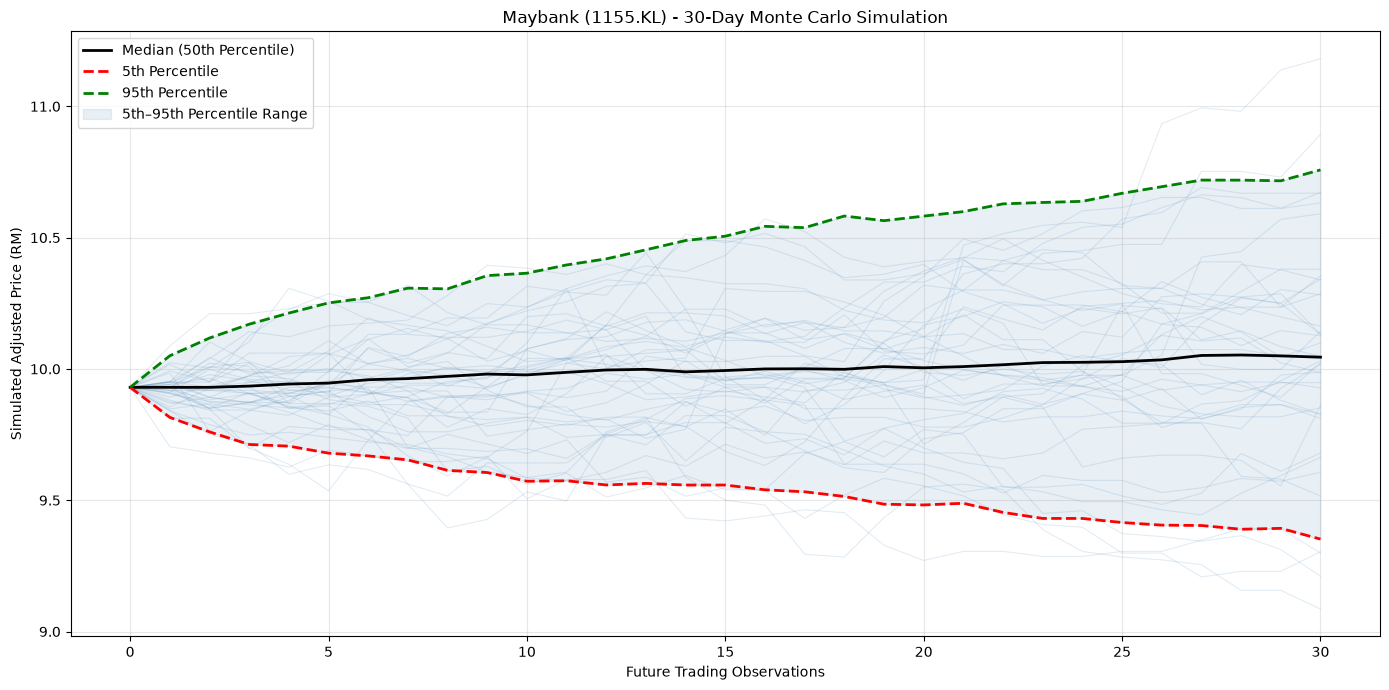

In [52]:

# Step 15.2: Visualise Monte Carlo Simulation

import numpy as np
import matplotlib.pyplot as plt
import os

# Create trading observation numbers (0 to 30)
days = np.arange(n_days + 1)

# Calculate percentiles at each observation
median_path = np.median(sim_prices, axis=1)

p05_path = np.percentile(sim_prices, 5, axis=1)

p95_path = np.percentile(sim_prices, 95, axis=1)

# Create chart
plt.figure(figsize=(14, 7))

# Plot 40 sample simulation paths
plt.plot(
    days,
    sim_prices[:, :40],
    color="steelblue",
    alpha=0.15,
    linewidth=0.8
)

# Plot the median path
plt.plot(
    days,
    median_path,
    color="black",
    linewidth=2,
    label="Median (50th Percentile)"
)

# Plot the downside scenario
plt.plot(
    days,
    p05_path,
    color="red",
    linestyle="--",
    linewidth=2,
    label="5th Percentile"
)

# Plot the upper scenario
plt.plot(
    days,
    p95_path,
    color="green",
    linestyle="--",
    linewidth=2,
    label="95th Percentile"
)

# Shade the 5th–95th percentile range
plt.fill_between(
    days,
    p05_path,
    p95_path,
    color="steelblue",
    alpha=0.12,
    label="5th–95th Percentile Range"
)

# Add titles and labels
plt.title(
    "Maybank (1155.KL) - 30-Day Monte Carlo Simulation"
)

plt.xlabel("Future Trading Observations")
plt.ylabel("Simulated Adjusted Price (RM)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart for GitHub
os.makedirs("outputs/figures", exist_ok=True)

plt.savefig(
    "outputs/figures/maybank_monte_carlo_simulation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [53]:

# Step 15.3: Save Monte Carlo Summary

import pandas as pd

# Create summary table
monte_carlo_summary = pd.DataFrame({
    "Trading Observation": days,
    "Median Price (RM)": median_path,
    "5th Percentile (RM)": p05_path,
    "95th Percentile (RM)": p95_path
})

# Save to CSV
monte_carlo_summary.to_csv(
    "outputs/maybank_monte_carlo_summary.csv",
    index=False
)

# Display last five observations
display(monte_carlo_summary.tail())

print("Monte Carlo summary saved successfully!")


,Trading Observation,Median Price (RM),5th Percentile (RM),95th Percentile (RM)
26,26,10.034621,9.405266,10.694019
27,27,10.051328,9.403822,10.719166
28,28,10.053091,9.389534,10.718993
29,29,10.049788,9.392989,10.716496
30,30,10.044777,9.352017,10.758058


Monte Carlo summary saved successfully!
